In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
dataset_path = '/content/drive/MyDrive/dataset'
if os.path.exists(dataset_path):
    print(f"Contents of {dataset_path}:")
    for item in os.listdir(dataset_path):
        print(item)
else:
    print(f"The dataset path {dataset_path} does not exist. Please check the path and ensure your drive is mounted correctly.")

Contents of /content/drive/MyDrive/dataset:
train
train.cache
val
.ipynb_checkpoints
val.cache


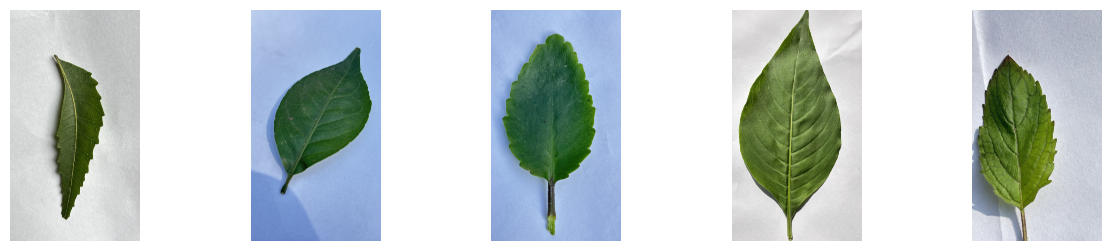

In [ ]:
import matplotlib.pyplot as plt
import os
import random
from PIL import Image

path = "/content/drive/MyDrive/dataset/train/healthy"

images = os.listdir(path)
sample = random.sample(images, 5)

plt.figure(figsize=(15,3))

for i,img in enumerate(sample):
    plt.subplot(1,5,i+1)
    image = Image.open(os.path.join(path,img))
    plt.imshow(image)
    plt.axis("off")

plt.show()

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 29.5 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
model = YOLO("yolov8s-cls.pt")

In [ ]:
model.train(
    data=os.path.join("/content/drive/MyDrive/dataset"),
    epochs=5,
    imgsz=224,
    batch = 16
)

Ultralytics 8.4.62 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/dataset, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7dfd3b748e00>
curves: []
curves_results: []
fitness: 0.987500011920929
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.9750000238418579, 'metrics/accuracy_top5': 1.0, 'fitness': 0.987500011920929}
save_dir: PosixPath('/content/runs/classify/train')
speed: {'preprocess': 0.23300347500168073, 'inference': 1.18257390000025, 'loss': 0.000466799998832812, 'postprocess': 0.0005974499984517934}
top1: 0.9750000238418579
top5: 1.0

In [ ]:
model.val()

Ultralytics 8.4.62 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8s-cls summary (fused): 30 layers, 5,077,762 parameters, 0 gradients, 12.4 GFLOPs
train: /content/drive/MyDrive/dataset/train... found 160 images in 2 classes ✅ 
val: /content/drive/MyDrive/dataset/val... found 40 images in 2 classes ✅ 
test: None...
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 619.7±24.5 MB/s, size: 5261.9 KB)
val: Scanning /content/drive/MyDrive/dataset/val... 40 images, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 12.0Mit/s 0.0s
val: /content/drive/MyDrive/dataset/val/diseased/IMG_20251126_143717.jpg: corrupt JPEG restored and saved
val: /content/drive/MyDrive/dataset/val/diseased/IMG_20251126_143718.jpg: corrupt JPEG restored and saved
val: /content/drive/MyDrive/dataset/val/diseased/IMG_20251126_143921.jpg: corrupt JPEG restored and saved
val: /content/drive/MyDrive/dataset/val/diseased/IMG_20260128_123113_1.jpg: corrupt JPEG restored and saved
val: /content/drive/MyDrive/dataset/va

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7dfce8215a60>
curves: []
curves_results: []
fitness: 0.987500011920929
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.9750000238418579, 'metrics/accuracy_top5': 1.0, 'fitness': 0.987500011920929}
save_dir: PosixPath('/content/runs/classify/val')
speed: {'preprocess': 0.20055627500141782, 'inference': 5.06537219999359, 'loss': 0.0009148499998445914, 'postprocess': 0.0015640000015082478}
top1: 0.9750000238418579
top5: 1.0

In [ ]:
results = model.predict("/content/drive/MyDrive/Dataset of Herbal plants/Arosh Kolai/Healthy/IMG_5984.jpeg")
print(results)


image 1/1 /content/drive/MyDrive/Dataset of Herbal plants/Arosh Kolai/Healthy/IMG_5984.jpeg: 224x224 healthy 0.60, diseased 0.40, 3.6ms
Speed: 136.3ms preprocess, 3.6ms inference, 0.1ms postprocess per image at shape (1, 3, 224, 224)
[ultralytics.engine.results.Results object with attributes:

boxes: None
keypoints: None
masks: None
names: {0: 'diseased', 1: 'healthy'}
obb: None
orig_img: array([[[192, 181, 177],
        [194, 183, 179],
        [197, 186, 182],
        ...,
        [ 38, 178, 125],
        [ 37, 177, 124],
        [ 36, 176, 123]],

       [[190, 179, 175],
        [192, 181, 177],
        [195, 184, 180],
        ...,
        [ 38, 178, 125],
        [ 37, 177, 124],
        [ 37, 177, 124]],

       [[188, 177, 173],
        [190, 179, 175],
        [193, 182, 178],
        ...,
        [ 39, 179, 126],
        [ 39, 179, 126],
        [ 39, 179, 126]],

       ...,

       [[  7,  43,  21],
        [  7,  43,  21],
        [  7,  43,  21],
        ...,
        [20

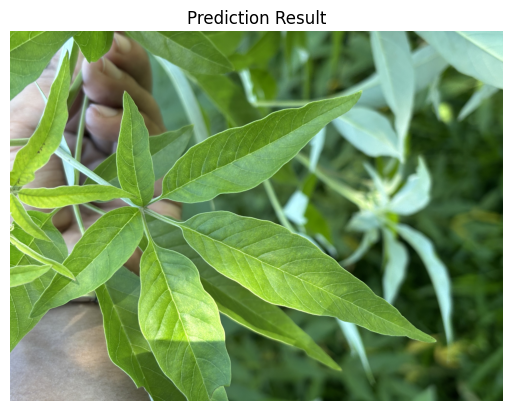

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("/content/drive/MyDrive/Dataset of Herbal plants/Arosh Kolai/Healthy/IMG_5984.jpeg")

plt.imshow(img)
plt.axis("off")
plt.title("Prediction Result")
plt.show()

In [ ]:
import os
import shutil

# Path where the model was trained and saved (from the output of model.train())
source_model_dir = '/content/runs/classify/train3/weights'
source_model_path = os.path.join(source_model_dir, 'best.pt')

# Destination path in Google Drive
destination_drive_folder = '/content/drive/MyDrive/yolov8_models'
destination_model_path = os.path.join(destination_drive_folder, 'yolov8s-cls_custom_dataset.pt')

# Create the destination folder if it doesn't exist
os.makedirs(destination_drive_folder, exist_ok=True)

if os.path.exists(source_model_path):
    try:
        shutil.copy(source_model_path, destination_model_path)
        print(f"Model successfully downloaded to: {destination_model_path}")
    except Exception as e:
        print(f"Error copying model: {e}")
else:
    print(f"Source model not found at {source_model_path}. Please ensure the model trained successfully.")

Source model not found at /content/runs/classify/train3/weights/best.pt. Please ensure the model trained successfully.
